In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import control as ct
import scipy.signal as signal

In [2]:
K = 15
G1 = ct.tf([1], [1, 0])
G2 = ct.tf([1], [1, 2])
G3 = ct.tf([1], [1, 7])

# Gain of the system K 
print(f'The gain of the system K: {K}')

# Actual Plant 
G = K * G1 * G2 * G3
print(f'The transfer function of the system G(s): {G}')

# Feedback Loop Transfer Function
H = 1 
print(f'The transfer function of the feedback loop H(s): {H}')

# Open Loop Transfer Funtion 
L = G * H
print(f'The transfer function of the open loop system L(s): {L}')

# Closed Loop Transfer Funtion
CL = ct.feedback(G, H)
print(f'The transfer function of the closed loop system CL(s): {CL}')

The gain of the system K: 15
The transfer function of the system G(s): <TransferFunction>: sys[6]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

          15
  ------------------
  s^3 + 9 s^2 + 14 s
The transfer function of the feedback loop H(s): 1
The transfer function of the open loop system L(s): <TransferFunction>: sys[8]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

          15
  ------------------
  s^3 + 9 s^2 + 14 s
The transfer function of the closed loop system CL(s): <TransferFunction>: sys[10]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

            15
  -----------------------
  s^3 + 9 s^2 + 14 s + 15


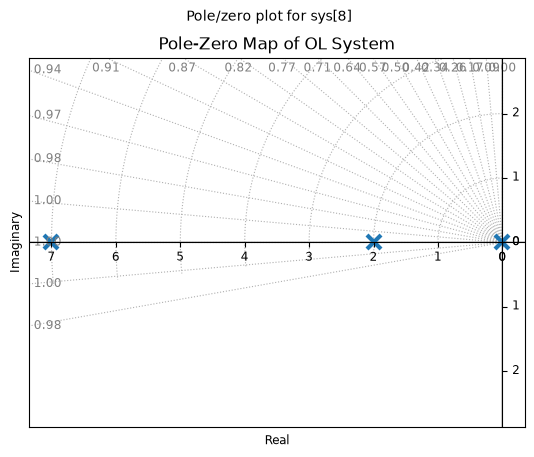

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


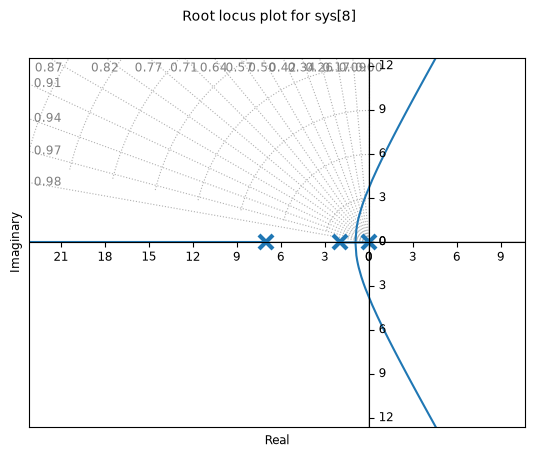

DC gain for OL= inf
Zeros of OL= []
Poles of OL= [-7.+0.j -2.+0.j  0.+0.j]
Dominant stable OL pole(s): [-2.+0.j]
Dominant OL pole (p1) = (-2+0j)
Dominant OL pole (p1) in abs value = 2.0


In [3]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(L, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(L, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(L)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(L)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(L)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_do = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

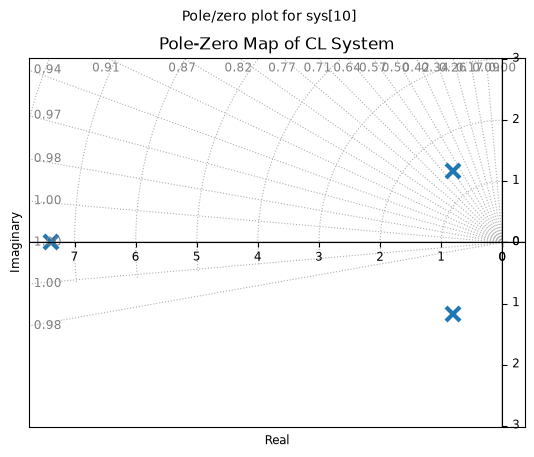

DC gain for CL= 1.0
Zeros of CL= []
Poles of CL= [-7.37803105+0.j         -0.81098447+1.17276038j -0.81098447-1.17276038j]
    Eigenvalue (pole)       Damping     Frequency
               -7.378             1         7.378
    -0.811    +1.173j        0.5688         1.426
    -0.811    -1.173j        0.5688         1.426
Natural frequency of poles (Wn) = [7.37803105 1.42585509 1.42585509]
Damping ratio zeta of poles (Z) = [1.         0.56877061 0.56877061]
Poles = [-7.37803105+0.j         -0.81098447+1.17276038j -0.81098447-1.17276038j]
Poles of CL= [-7.37803105+0.j         -0.81098447+1.17276038j -0.81098447-1.17276038j]
Dominant stable CL pole(s): [-0.81098447+1.17276038j -0.81098447-1.17276038j]
Dominant CL pole (p1) = (-0.810984473987753+1.1727603844639392j)
Dominant CL pole (p1) in abs value = 1.4258550895575604


Dominant Pole: (-0.810984473987753+1.1727603844639392j)
Natural frequency (wn): 1.4258550895575606 rad/s
Damping ratio (zeta, z): 0.5687706134565186
Decay rate (sigma): 

In [4]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(CL, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(CL)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(CL)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(CL)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(CL)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_d = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




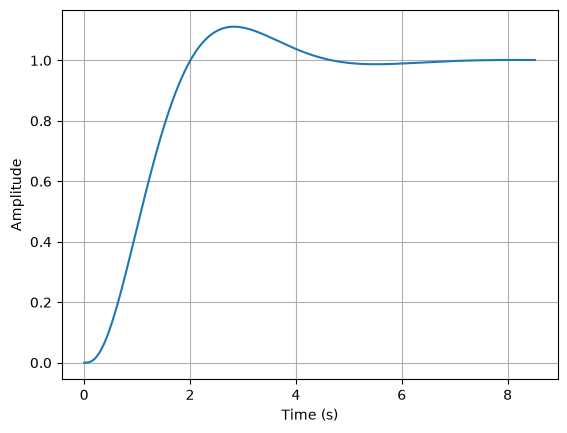

Rise Time (Tr): 1.29 seconds
Settling Time (Ts): 4.27 seconds
Peak Time (Tp): 2.83 seconds
Overshoot (%): 11.15%
Final Value = 1.0
Steasy state error (ess) = 0.0


In [5]:
plt.figure()
t, y = ct.step_response(CL)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(CL)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

In [6]:
# Type of the system = 1 
# So, Kv is specified, Kv = lim:s->0 sG(s)Gc(s) 

A1 = K*G2*G3
Kv_old = np.abs(A1(0))
print(f'Old velocity error constant (Kv_old) = {Kv_old}')

ess_old = 1/Kv_old
print(f'Old error (ess) = {ess_old}')

Old velocity error constant (Kv_old) = 1.0714285714285714
Old error (ess) = 0.9333333333333333


In [7]:
# Required Specification 
# ess = 0.01 

In [8]:
# Type of the system = 1 
# So, Kv is specified, Kv = lim:s->0 sG(s)Gc(s)

ess_new = 0.01 
print(f'Required error (ess) = {ess_new}')
Kv_new = 1 / ess_new
print(f'Required velocity error constant (Kv_new) = {Kv_new}')

Required error (ess) = 0.01
Required velocity error constant (Kv_new) = 100.0


In [9]:
beta = Kv_new / Kv_old
print(f'Beta = {beta}')

# Nearest open loop pole
# -1/T = 10% of the nearest open or close loop pole
# P_do  np.real(p_do)
T = -1/(0.1*np.real(p_do))
print(f'T = {T}')

zc = 1/T
print(f'Zero of the lag compensator (zc) = {zc}')
pc = 1/(T*beta)
print(f'Pole of the lag compensator (pc) = {pc}')

# Lag Compensator transfer function without gain 
Gc = ct.tf([1, zc], [1, pc])
print(f'Lead Compensator Transfer Function without gain (Gc) = {Gc}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole Gc(Sd) = {Gc(p_do)}')
print(f'Open Loop Gain at required Pole in absolute form Gc(Sd) = {np.abs(Gc(p_do))}')
print(f'Open Loop Phase at required Pole Gc(Sd) = {np.angle(Gc(p_do))}')
print(f'Open Loop Phase at required Pole in Degrees Gc(Sd) = {np.rad2deg(np.angle(Gc(p_do)))}')

Beta = 93.33333333333334
T = 5.0
Zero of the lag compensator (zc) = 0.2
Pole of the lag compensator (pc) = 0.0021428571428571425
Lead Compensator Transfer Function without gain (Gc) = <TransferFunction>: sys[18]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    s + 0.2
  ------------
  s + 0.002143
Open Loop Gain at required Pole Gc(Sd) = (0.9009653199856991-0j)
Open Loop Gain at required Pole in absolute form Gc(Sd) = 0.9009653199856991
Open Loop Phase at required Pole Gc(Sd) = -0.0
Open Loop Phase at required Pole in Degrees Gc(Sd) = -0.0


In [10]:
# Lead compensator gain 
Kc = 1/(np.abs(G(p_d)*Gc(p_d)))
print(f'Lead Compensator Gain (Kc) = {Kc}')

Lead Compensator Gain (Kc) = 1.0773344265678029


In [11]:
Gc1 = Kc * Gc
print(f'Lead Compensator Transfer Function with gain (Gc1) = {Gc1}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole G(Sd) = {Gc(p_d)}')
print(f'Open Loop Gain at required Pole in absolute form G(Sd) = {np.abs(Gc(p_d))}')
print(f'Open Loop Phase at required Pole G(Sd) = {np.angle(Gc(p_d))}')
print(f'Open Loop Phase at required Pole in Degrees G(Sd) = {np.rad2deg(np.angle(Gc(p_d)))}')

Lead Compensator Transfer Function with gain (Gc1) = <TransferFunction>: sys[20]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  1.077 s + 0.2155
  ----------------
    s + 0.002143
Open Loop Gain at required Pole G(Sd) = (0.9211491193672979-0.11432793164976401j)
Open Loop Gain at required Pole in absolute form G(Sd) = 0.9282168798650784
Open Loop Phase at required Pole G(Sd) = -0.12348298996308218
Open Loop Phase at required Pole in Degrees G(Sd) = -7.075054166540914


In [12]:
A2 = K*G2*G3*Gc1 
# Type of system = 1 i.e. pole at origin = 1 
# so the velocity error constant, Kv = lim:s->0 sG(s)Gc(s)
kv = np.abs(A2(0))
print(f'velocity error constant kv = {kv}')

ess = 1/kv
print(f'steady state error ess = {ess}')

velocity error constant kv = 107.73344265678031
steady state error ess = 0.009282168798650788


In [13]:
A3 = G*Gc1 
print(f'System Transfer Function with compensator A3(s) = {A3}')
A4 = A3 * H
print(f'open loop system transfer function with compensator A4(s) = {A4}')
A5 = ct.feedback(A3, 1)
print(f'Closed loop system transfer function with compensator A5(s) = {A5}')

System Transfer Function with compensator A3(s) = <TransferFunction>: sys[25]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

            16.16 s + 3.232
  ------------------------------------
  s^4 + 9.002 s^3 + 14.02 s^2 + 0.03 s
open loop system transfer function with compensator A4(s) = <TransferFunction>: sys[27]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

            16.16 s + 3.232
  ------------------------------------
  s^4 + 9.002 s^3 + 14.02 s^2 + 0.03 s
Closed loop system transfer function with compensator A5(s) = <TransferFunction>: sys[29]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                 16.16 s + 3.232
  ---------------------------------------------
  s^4 + 9.002 s^3 + 14.02 s^2 + 16.19 s + 3.232


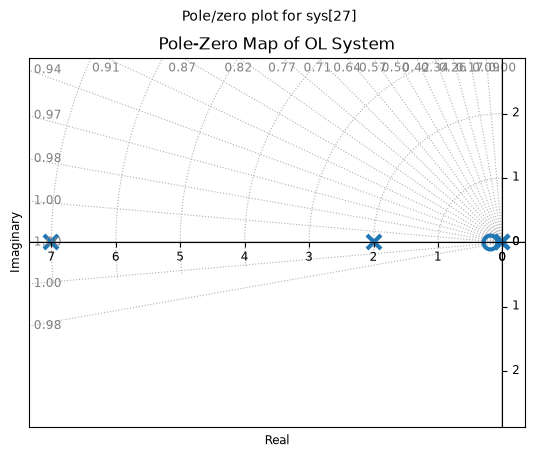

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


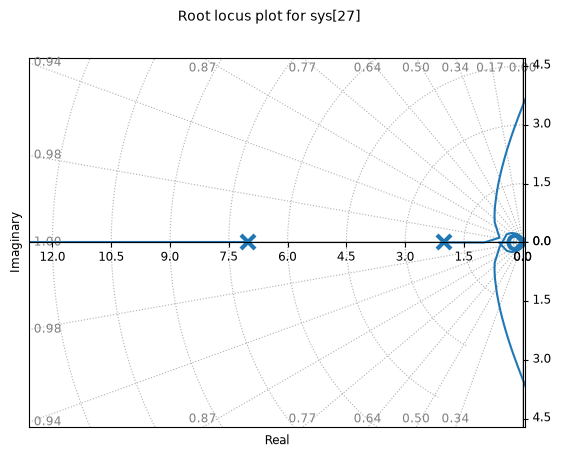

DC gain for OL= inf
Zeros of OL= [-0.2+0.j]
Poles of OL= [-7.00000000e+00+0.j -2.00000000e+00+0.j -2.14285714e-03+0.j
  0.00000000e+00+0.j]
Dominant stable OL pole(s): [-0.00214286+0.j]
Dominant OL pole (p1) = (-0.002142857142857142+0j)
Dominant OL pole (p1) in abs value = 0.002142857142857142


In [14]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A4, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(A4, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(A4)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(A4)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(A4)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

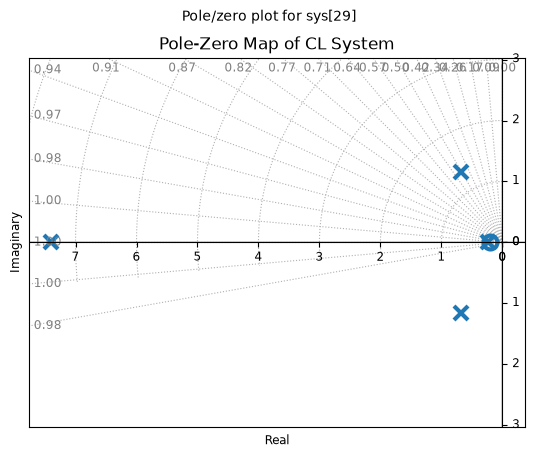

DC gain for CL= 1.0
Zeros of CL= [-0.2+0.j]
Poles of CL= [-7.39430017+0.j         -0.68242272+1.15458209j -0.68242272-1.15458209j
 -0.24299725+0.j        ]
    Eigenvalue (pole)       Damping     Frequency
               -7.394             1         7.394
   -0.6824    +1.155j        0.5088         1.341
   -0.6824    -1.155j        0.5088         1.341
               -0.243             1         0.243
Natural frequency of poles (Wn) = [7.39430017 1.3411788  1.3411788  0.24299725]
Damping ratio zeta of poles (Z) = [1.         0.50882307 0.50882307 1.        ]
Poles = [-7.39430017+0.j         -0.68242272+1.15458209j -0.68242272-1.15458209j
 -0.24299725+0.j        ]
Poles of CL= [-7.39430017+0.j         -0.68242272+1.15458209j -0.68242272-1.15458209j
 -0.24299725+0.j        ]
Dominant stable CL pole(s): [-0.24299725+0.j]
Dominant CL pole (p1) = (-0.24299724854982088+0j)
Dominant CL pole (p1) in abs value = 0.24299724854982088


Dominant Pole: (-0.24299724854982088+0j)
Natural frequency (

In [15]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A5, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(A5)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(A5)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(A5)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(A5)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




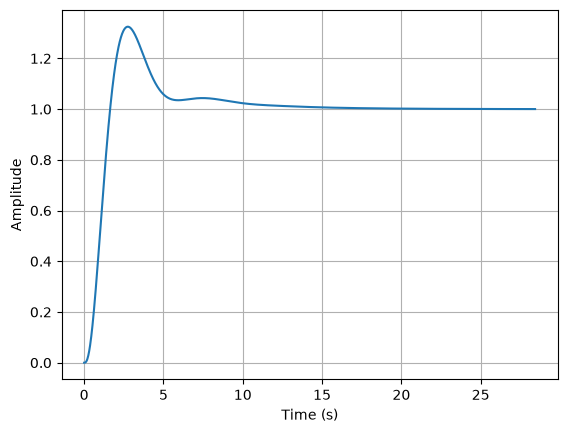

Rise Time (Tr): 1.05 seconds
Settling Time (Ts): 10.50 seconds
Peak Time (Tp): 2.75 seconds
Overshoot (%): 32.51%
Final Value = 1.0
Steasy state error (ess) = 0.0


In [16]:
plt.figure()
t, y = ct.step_response(A5)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(A5)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

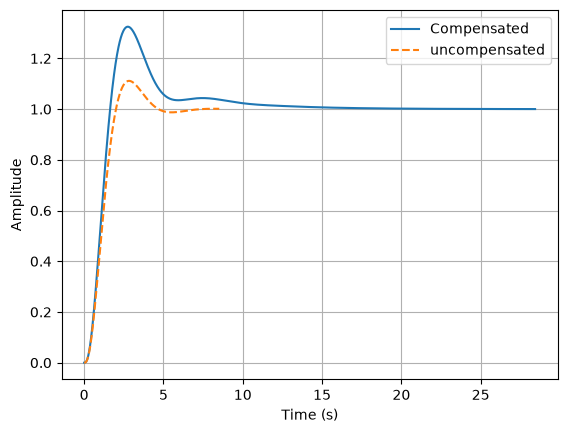

In [17]:
plt.figure()
t1, y1 = ct.step_response(A5)
t2, y2 = ct.step_response(CL)

plt.plot(t1, y1, label='Compensated')
plt.plot(t2, y2, label='uncompensated', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.show()